# Project 2 — Q5: Cell Matching × Segmentation

**NYU Tandon · CS-GY 6643 · Fall 2026**  
**Team member(s) / NetID(s):** To be added

A compact **traditional computer-vision** pipeline: background subtraction, Gaussian blob responses, Hessian shape filtering, marker-controlled watershed, correlation-based registration, RANSAC refinement and one-to-one assignment. No pretrained models, neural networks, manual masks, test labels or sample-specific prediction branches.

**Target: 0.70 combined score, not pixel accuracy.** The measured results below determine whether that target was reached. This notebook and `cell_matching.py` reproduce the candidate CSV; no Kaggle upload or official leaderboard score is claimed.

## Data, sources and validation

[Competition](https://www.kaggle.com/competitions/testingpj-2): user-downloaded data contains 47 training regions from three mice and 29 hidden-test regions, with 152 native 16-bit TIFFs, 14,893 in-vivo cells, 5,516 ex-vivo cells and 1,139 verified pairs. Local hashes and dimensions are in `DATA_SOURCES.json`. Original images are loaded unchanged; normalization applies only to derived processing arrays.

**Sources:** Q5 handout §§4–6; L3 RANSAC (pp. 27–52), L4 filtering/segmentation/warping (pp. 42–104), L5 segmentation and registration guidance (pp. 11–38, 111). RLE follows L5 codelab cell 18: zero-based, row-major `start length`, empty string for an empty mask. Released mask bounds and visual overlays agree with this convention. The complete pipeline is a project adaptation. In particular, the codelab's use of known correspondence pairs for registration is **not** used at prediction time.

The handout metric is `0.25 PQ_invivo + 0.25 PQ_exvivo + 0.50 F1_match`. Mask true positives require **IoU > 0.75**. PQ is averaged over regions; matching counts are pooled before computing F1. A match is correct only when both masks pass IoU and the pair is verified. Unverified pairs are not biological negatives, although unverified predictions receive no matching credit.

`subject_db6b8b` is held out (18 regions); the other two mice provide 29 development regions. Exploratory mask variants used four development regions, then final thresholds and matching gates were selected on all 29 development regions. Parameters were frozen before held-out scoring. Subject IDs are used only to split evaluation, never inside prediction. A single held-out mouse is a limited estimate of generalization.

**Live rules/scorer limitation:** Kaggle's unauthenticated data API returned HTTP 401. This is a local reconstruction of the supplied handout metric, not a verified copy of the official scorer. Empty/empty PQ and all-empty matching F1 are defined as 1 locally; those cases do not occur in the supplied labeled data.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy import ndimage as ndi
from skimage.segmentation import mark_boundaries
from matplotlib.patches import ConnectionPatch
from cell_matching import (PARAMETERS, read_pair, normalize, predict_pair, decode_rle,
                           centers, evaluate, summarize, write_submission)

root = Path("Data")
out = Path("outputs/q5")
out.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(root / "training/train_ground_truth.csv", dtype=str)
sample = pd.read_csv(root / "sample_submission.csv", dtype=str)
assert list(train.columns) == list(sample.columns)
assert train.sample_id.is_unique and sample.sample_id.is_unique
held_out = train.sample_id.str.split("__").str[0] == "subject_db6b8b"
print(f"Development: {(~held_out).sum()} regions; held out: {held_out.sum()}; test: {len(sample)}")
PARAMETERS

Development: 29 regions; held out: 18; test: 29


{'invivo': {'sigma': 2.5, 'threshold': 0.025, 'fraction': 0.15, 'dilation': 1},
 'exvivo': {'sigma': 3, 'threshold': 0.12, 'fraction': 0.15, 'blobness': 0.6},
 'matching': {'gate': 6, 'cutoff': 0.1}}

## 1. Instance segmentation

Normalize between intensity percentiles 1 and 99.8, subtract a broad Gaussian background, and find peaks of a difference-of-Gaussians response. The ex-vivo detector additionally uses Hessian curvature balance: round bright peaks curve in two directions, whereas a thin fiber mainly curves across its width. Grow separate regions with watershed, threshold each relative to its peak, bound growth to 12 pixels from a seed and reject areas outside 25–350 pixels. In-vivo regions expand by one pixel, which improved the overly tight initial boundaries on development images.

The same modality parameters apply to every region. Candidate threshold, smoothing, boundary, dilation, ellipse-fit and Hessian variants were compared; ellipse fitting and fixed global thresholds were weaker. Final selection gave development PQ approximately **0.347 in vivo / 0.178 ex vivo**. These are development results, not held-out or leaderboard scores. Missing dim cells, merged cells and bright processes remain limitations.

The helper file contains the full implementation; no prior notebook is executed or imported. The panels below compare an automatically centered training crop with its annotations. Crop selection is **display only** and does not influence prediction.

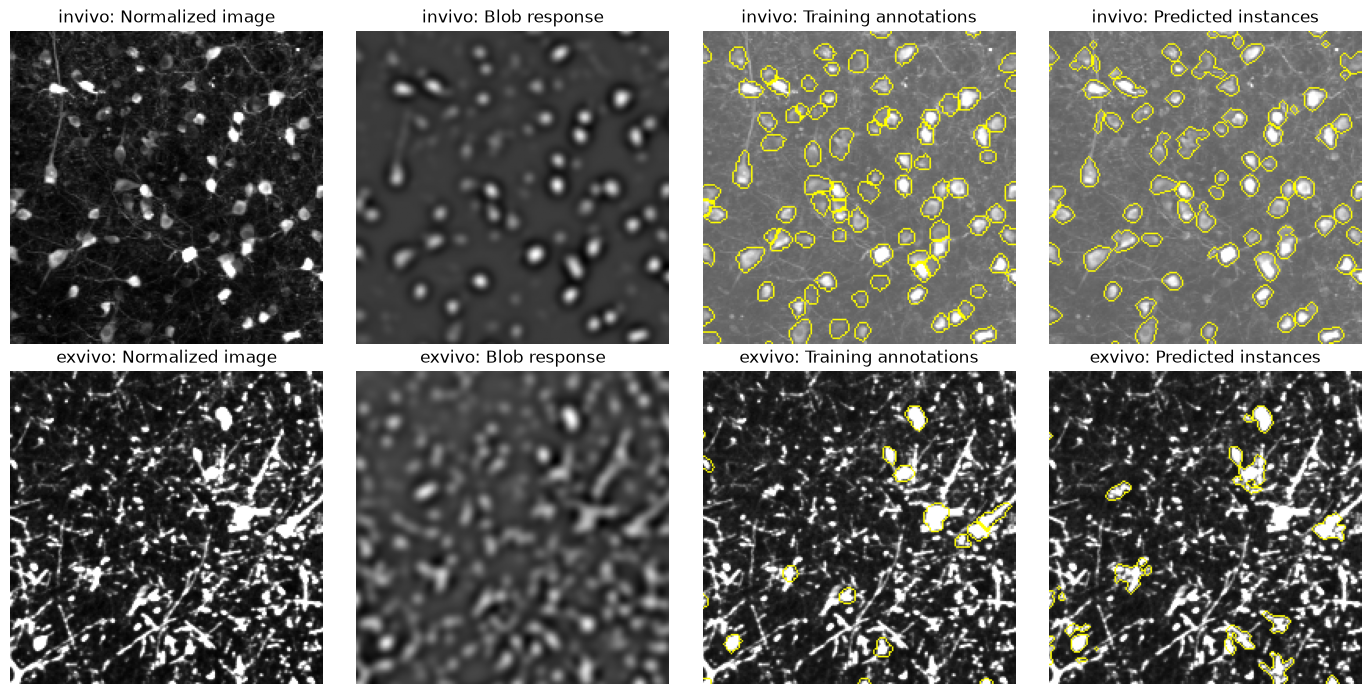

In [2]:
example = train.loc[~held_out].iloc[0]
images = read_pair(root / "training", example.sample_id)
labels, pairs, matrix, correlation = predict_pair(images)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, (image, prediction, modality) in enumerate(zip(images, labels, ["invivo", "exvivo"])):
    truth = np.zeros(image.shape, np.int32)
    for i, rle in enumerate(json.loads(example[modality + "_instances"]).values(), 1):
        truth[decode_rle(rle, image.shape)] = i
    y, x = np.median(np.argwhere(truth > 0), axis=0).astype(int)
    crop = np.s_[max(0, y-100):y+100, max(0, x-100):x+100]
    image_float = normalize(image)
    signal = np.maximum(ndi.gaussian_filter(image_float, 1) - ndi.gaussian_filter(image_float, 10), 0)
    sigma = PARAMETERS[modality]["sigma"]
    response = ndi.gaussian_filter(signal, sigma) - ndi.gaussian_filter(signal, 1.6*sigma)
    pictures = [image_float[crop], response[crop], mark_boundaries(image_float[crop], truth[crop]),
                mark_boundaries(image_float[crop], prediction[crop])]
    for ax, picture, title in zip(axes[row], pictures, ["Normalized image", "Blob response", "Training annotations", "Predicted instances"]):
        ax.imshow(picture, cmap="gray")
        ax.set_title(f"{modality}: {title}")
        ax.axis("off")
    tifffile.imwrite(out / f"example_{modality}_labels.tif", prediction.astype(np.uint16))
plt.tight_layout()
plt.savefig(out / "segmentation_diagnostics.png", dpi=150)
plt.show()

## 2. Registration and one-to-one matching

Compare band-pass image responses at quarter resolution. Search image-derived translations over a coarse rotation/scale grid, then refine around the best correlation peak. The rotation range ±40° and scale range 0.8–1.2 (locally refined by ±0.1) are shared search bounds, supported by development examples; they are not known transforms. Different frame sizes do not determine cell scale. Unseen transforms outside these bounds are a limitation.

If correlation is sufficient, refine with RANSAC using mutual nearest **predicted** cell centers, then solve distance-gated Hungarian assignment with dummy unmatched columns. Reject pairs outside the selected six-pixel gate; retain empty matches when alignment evidence is insufficient. No ground-truth pairs enter registration or matching. The correlation cutoff is a heuristic, not a calibrated probability, and still permits wrong alignments.

SIFT/RootSIFT and simple point-pattern voting produced incorrect alignments in development trials; the retained correlation method was more useful but remains unreliable under missing cells, deformation and modality changes. It is the main reason the 0.70 target is difficult with this baseline.

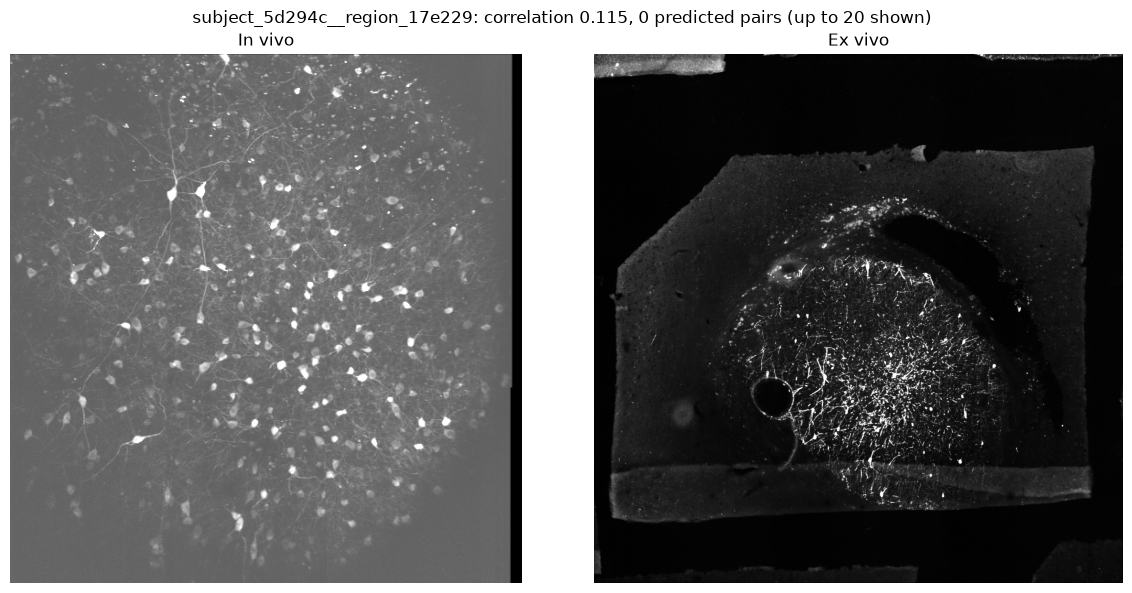

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, image, title in zip(axes, images, ["In vivo", "Ex vivo"]):
    ax.imshow(normalize(image), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
a, b = [centers(mask) for mask in labels]
for i, j in pairs[:20]:
    fig.add_artist(ConnectionPatch(a[i-1], b[j-1], "data", "data", axesA=axes[0], axesB=axes[1],
                                  color="lime", linewidth=.7, alpha=.7))
fig.suptitle(f"{example.sample_id}: correlation {correlation:.3f}, {len(pairs)} predicted pairs (up to 20 shown)")
plt.tight_layout()
plt.savefig(out / "matching_diagnostics.png", dpi=150)
plt.show()

## 3. Local evaluation with frozen parameters

Run predictions from images only, then compare with training annotations. Record every region, including failures. The held-out result is evaluated once after parameter selection; no subsequent parameter adjustment uses it. Passing file-format tests or matching a synthetic translated image is not evidence of real-image accuracy.

In [4]:
records = []
for row in train.itertuples(index=False):
    prediction, predicted_pairs, _, confidence = predict_pair(read_pair(root / "training", row.sample_id))
    records.append(dict(sample_id=row.sample_id,
                        split="held_out" if row.sample_id.split("__")[0] == "subject_db6b8b" else "development",
                        correlation=confidence, **evaluate(prediction, predicted_pairs, row)))
metrics = pd.DataFrame(records)
metrics.to_csv(out / "validation_per_region.csv", index=False)
summary = pd.DataFrame({split: summarize(group) for split, group in metrics.groupby("split")}).T
summary.to_csv(out / "validation_summary.csv")
display(summary.round(4))
score = summary.loc["held_out", "score"]
print(f"Held-out combined score: {score:.4f}; target 0.7000 {'reached' if score >= .7 else 'NOT reached'}")

,pq_invivo,pq_exvivo,f1_match,score
development,0.3472,0.1777,0.0162,0.1393
held_out,0.4089,0.2309,0.0000,0.1600


Held-out combined score: 0.1600; target 0.7000 NOT reached


## 4. Generate and validate the candidate submission

Use the released sample IDs in their original order. Encode native-size masks as JSON RLE dictionaries and one-to-one ID pairs as JSON arrays. Check schema, exact sample coverage, nonempty mask bounds, encode/decode round trips, pair references, pair uniqueness and CSV round trips. All predicted masks are generated from each image; there are no hand-edited answers.

The following cell writes a **local candidate**, not a Kaggle submission. Reproduce it independently with:

```bash
.venv/bin/python cell_matching.py --data Data --output "Kaggle Submissions/classical_submission.csv"
```

Run contract tests with `.venv/bin/python -m unittest test_cell_matching.py`. Existing pinned dependencies suffice.

In [5]:
submission = write_submission(root, "Kaggle Submissions/classical_submission.csv")
print(f"Validated {len(submission)} rows; saved classical_submission.csv")
display(submission[["sample_id"]].head())

subject_78b6a7__region_33daed: 354/116 cells, 0 pairs, correlation=0.086


subject_78b6a7__region_64dd4d: 249/66 cells, 0 pairs, correlation=0.119


subject_78b6a7__region_7754ed: 327/63 cells, 0 pairs, correlation=0.098


subject_78b6a7__region_798993: 366/82 cells, 0 pairs, correlation=0.081


subject_78b6a7__region_7c48e3: 342/92 cells, 0 pairs, correlation=0.078


...

subject_d7a97c__region_d472db: 332/111 cells, 0 pairs, correlation=0.089


subject_d7a97c__region_dd13e1: 316/37 cells, 0 pairs, correlation=0.089


subject_d7a97c__region_f24078: 332/155 cells, 1 pairs, correlation=0.101


Validated 29 rows; saved classical_submission.csv


,sample_id
0,subject_78b6a7__region_33daed
1,subject_78b6a7__region_64dd4d
2,subject_78b6a7__region_7754ed
3,subject_78b6a7__region_798993
4,subject_78b6a7__region_7c48e3


## Results, limitations and disclosure

**Held-out result: 0.1600, below the 0.70 target.** In-vivo PQ: 0.4089; ex-vivo PQ: 0.2309; matching F1: 0.0000. None of the 7 accepted held-out pairs was correct. Only 99 of 562 verified pairs have both predicted masks above IoU 0.75. Even perfect correspondence selection with these fixed masks would give at most **0.310 combined score** (`0.25 PQ_iv + 0.25 PQ_ex + 0.5 × 2r/(r+verified)`). Both segmentation and matching therefore need improvement. Use these measurements, not the requested target, when reporting performance. The strict IoU cutoff couples small mask errors to matching failures. The method misses dim/irregular cells, mistakes some processes for cells and cannot reliably recover cross-modal alignment from few shared detections. A rigid/similarity model also cannot fully describe tissue deformation. The generated CSV is a reproducible classical baseline, **not a claim of 70% accuracy or submission readiness**.

The supplied handout is the metric source; live scorer details and leaderboard performance remain unverified. No external datasets, neural models, hidden labels, manual mask corrections or per-test-region tuning were used. Team identity and the separate final report remain to be completed. README is intentionally unchanged during development.

## AI assistance and prompt record

OpenAI Codex assisted with source review, classical implementation, development experiments, evaluation and submission-format checks. The actual prompt chain follows; no hidden reasoning is included.


# AI Assistance Record — Project 2

## Tools and scope

During initial setup on 2026-10-06, OpenAI Codex assisted with reading the previous project's workflow and both Project 2 handouts, preparing project instructions, downloading official Q1–Q4 data, initializing the Python environment, and creating Markdown-only notebook scaffolds. No question was solved during setup. Later source review and Q1 implementation are recorded chronologically below.

Keep actual user prompts in chronological order. Add subsequent assistance here and include the required disclosure/prompt chain in final deliverables. Do not reconstruct unavailable prompts or include hidden model reasoning.

## Request 1 — 2026-10-06

The user referenced `../Project1/AGENTS.md` and attached a screenshot of the previous project's directory structure. The request text was:

> Go through the AGENTS.md file for the previous project of this course, we will be following similar workflow for this project as well. Understand the requirements for this project by going through the project material present in the two pdfs present in the project root. Create a AGENTS.md file similar to one uploaded from the previous project with emaphasis on simple and minila code, we will follow the similar project structure as the project 1. For this task create the directories and download the data for Q1-4 we will solve this in subsequent tasks and the solutions and concepts used in it will the foundation upon which will we solve the kaggle competition problem. Also initialize the virtual python environment and install the required libraries. Add basic README.md we wont update it  until after the project solution is finished and ready to submit. Just create the solution notebooks and just add Heading markdown cells with boilerplate information about what it contains don't add code yet. In next tasks I will provide the lecture slides and the codelab notbooks the concepts and code from will we will use to solve this assignment.

## Request 2 — 2026-10-06

> Commit and push the repository to [https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git](https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git)

Assistance: inspect the local and remote Git state, prepare the initial setup commit, and push it to the user-specified repository. Existing dataset, environment, and generated-output exclusions are retained.

## Request 3 — 2026-10-08

The user supplied Lecture 3, 4, 5, and 6 PDFs; their exact paths are recorded in `AGENTS.md` §6.

> Go through this slides and understand the concepts covered  in the lectures. Update the AGENTS.md briefly to use these concepts in the solutions

Assistance: review the four slide decks, map their concepts to Q1–Q5, and record the later deadline extension and Q5-specific guidance. No solution code or notebook changes.

## Request 4 — 2026-10-08

The message listed the four lecture PDFs; the corresponding local code notebooks were found in `../Lectures/CodeLabs/` and are identified in `AGENTS.md` §6.1.

> Go through these codelabs and understand the code and concepts discussed. We will use this code to solve the porblems.

Assistance: review four relevant local codelabs, record reusable snippets and adaptation issues, and check the supplied RLE functions on five synthetic masks. The solution notebooks and README were not changed; no models were downloaded or trained.

## Request 5 — 2026-10-08

> Using the concepts covered in the class, how do you solve the Question 1, give the overview of the approach before we code it

Assistance: explain a classical approach combining edge detection, pavement–grass color evidence, RANSAC line fitting, and pair geometry checks. No code was added in that turn.

## Request 6 — 2026-10-08

> great, let's code it in the notebook

Assistance: implement Q1 in `Q1to4Solution.ipynb`, adapting class RANSAC/SVD, Canny, thresholding and color-feature concepts; inspect the programmatically annotated result and retain diagnostics and explanations. Q2–Q5 and README remain unchanged. No hidden ground truth, manual coordinates, or learned models are used.

Validation: the notebook executed in a fresh kernel without cell errors, saved the annotated image and visible figures, and passed original-input hash and unchanged-placeholder checks. Residuals describe the fitted edge consensus, not hidden-ground-truth accuracy.

## Request 7 — 2026-10-08

> Use minimum code

## Request 8 — 2026-10-08

> Continue, use minimal tokens

Assistance: reduced Q1 from 133 to 67 nonblank code lines, removed redundant plots/table dependencies, and reran the notebook. The generated boundary image is byte-identical to the previous result.

## Request 9 — 2026-10-08

> For question1, add the final solution images in origianl image resolution and after that give the overview of the solution for question 2 using concepts covered in the class

Assistance: embed the original and annotated Q1 images at native 1280 × 850 resolution; outline SIFT matching, RANSAC homography estimation, perspective warping and mask-based compositing for Q2. No Q2 solution code added.

## Request 10 — 2026-10-08

> Great, add the solution for question 2 in the notebook with minimum code and optimizing the token usage

Assistance: implement a concise SIFT/ratio-test/RANSAC homography solution, warp and composite the replacement at original scene resolution, inspect the result, and document the small boundary mismatch caused by the curved cover. No manual coordinates or learned methods; README and Q3–Q5 remain unchanged.

## Request 11 — 2026-10-08

> You can add the code for question 2 to show important intermediate steps of the solution

Assistance: add concise visualizations of ratio-test matches, RANSAC inliers, the projected cover boundary, compositing mask and warped artwork. Display subsets/crops are labeled and computed automatically; fitting and final compositing remain unchanged.

## Request 12 — 2026-10-08

> Great, similary give the overview of solution for question 3 before coding

Assistance: inspect all six inputs and outline feature-based distortion correction, overlap inference, transform composition, canvas calculation and blending. No solution code added in that turn.

## Request 13 — 2026-10-08

> Great, let's add the solution to the notebook, keep the code minimum but include the important intermediate steps to the final solution, add final solution image in original dimentions

Assistance: implement Q3 with automatic padding-based distortion identification, SIFT/RANSAC overlap estimation, transform composition, image-derived cylindrical projection and feather blending. The cylinder addresses an observed projective-horizon failure in a flat-canvas trial. Include intermediate figures and the full-resolution panorama; document calibration assumptions and residual limitations. No hard-coded transforms/order, manual alignment, or high-level stitcher.

## Request 14 — 2026-10-08

> similarly give the overview of solution for question 4

Assistance: inspect the wildlife images and JSON clicks, and outline click-initialized GrabCut, conservative component cleanup, intermediate displays and original-resolution RGBA export.

## Request 15 — 2026-10-08

> Great let's code this into the notebook like previous questions

Assistance: implement classical click-guided GrabCut, compare initialization/spatial and edge-aware alternatives on the supplied images, and retain a common RGB-plus-spatial-cut baseline. Add diagnostic figures, original-resolution RGBA outputs, and explicit caveats about retained background and missing animal parts. No extra manual annotations or learned semantic models; image quality remains insufficient for a claim of complete animal isolation.

## Request 16 — Q4 refinement

> current solution is good but it's still very choppy and isn't very clode to the expected segments, in the first one the segment include large part of the tree along with the lizard, in second the large portion of the leopard's face is missing as well as the rear part and tail and part of rock and backgroud is also included, in third the the part of the tree is visible. Try to fix this, part of the problem it seems the subjects are clamoflaged well in the background. Try to resolve this issue without hardcoding the solutions. Try any other concepts of tricks from the lecture, use external knowledge if necessary. Course is derived from the Computer Vision: Algorithms and Applications textbook by Richard Szeliski. Check it for reference if anything from there might be usefule. Try to keep the code changes minimum and optimize the token usage.

## Request 17 — 2026-10-09

> Continue the work

Assistance: review Szeliski §§5.4–5.5 (February 2010 draft), compare classical texture/graph alternatives, and replace the Q4 color-cut intersection with shared Lab/Gabor superpixel geodesic segmentation and original-resolution GrabCut boundary refinement. No manual coordinates, mask corrections, learned models, new packages or per-image algorithm branches. Retain intermediate figures and explain both visual improvements and remaining bark/rock leakage and missing tail detail. README, Q1–Q3 implementation and Q5 remain unchanged.

## Request 18 — 2026-10-09

> Great now using these answers as foundation solve the kaggle competition with minimum code and optimize the token usage. Aim for 70 percent accuracy. Use only traditional Computer vision methods, stick to the competion description here is the link to competition [https://www.kaggle.com/competitions/testingpj-2](https://www.kaggle.com/competitions/testingpj-2)

Assistance: inspected Q5 handout and L5 RLE/registration examples; attempted official Kaggle access (data API HTTP 401), checked the empty Data folder and local Downloads archives, and requested the dataset path. Prepared the Q5 notebook's dataset/schema check, classical-only validation plan and codelab-derived RLE helpers. Real-image implementation, tuning, scoring and submission generation require the official dataset; no performance is claimed.

## Request 19 — 2026-10-09

> I have downloaded and copied the data in /Data directory

Assistance: verified the user-provided Q5 dataset and recorded 154 hashes; implemented a traditional blob/Hessian/watershed segmentation and correlation/RANSAC/Hungarian matching pipeline in `cell_matching.py`, with notebook diagnostics and a CSV generator. Compared segmentation and registration variants on development mice, selected shared modality parameters on 29 development regions, froze them before evaluating the remaining 18 regions, and retained all test IDs for submission generation. Six synthetic contract tests cover RLE, strict mask IoU, pair scoring, pooled F1, unmatched cells and image translation; these are not accuracy measurements. No learned models, test labels, manual corrections or per-test-ID tuning. The requested 0.70 score is a target, not an achieved or guaranteed result. Actual results are recorded in the notebook and `outputs/q5/validation_summary.csv`. No Kaggle upload performed.
